<a href="https://colab.research.google.com/github/Minhhieu3012/wifi-localization-data-mining/blob/part4b-dbscan-report/notebooks/members/05_dbscan_evaluation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## PHẦN 4B: GOM CỤM DỮ LIỆU VỚI DBSCAN, ĐÁNH GIÁ ARI VÀ TRỰC QUAN HÓA PCA 2D
**Phụ trách:** PHAN MINH HIẾU (`feature/part4b-dbscan-report`)
* **Mục tiêu:**
  1. Loại trừ cột nhãn `Room`, chuẩn hóa 7 thuộc tính liên tục bằng `StandardScaler`.
  2. Tìm tham số `eps` tối ưu bằng biểu đồ `k-distance` và thực hiện gom cụm bằng `DBSCAN`.
  3. Đánh giá kết quả gom cụm bằng độ đo **Adjusted Rand Index (ARI)** đối chiếu với `K-Means (k=4)`.
  4. Trực quan hóa kết quả gom cụm trên không gian giảm chiều **PCA 2D** (hiển thị rõ nhóm **Nhiễu / Noise** của DBSCAN).
  5. Nhận xét và Biện luận học thuật (So sánh K-Means vs. DBSCAN trên bộ dữ liệu WiFi Localization)

 ### 1. Loại trừ cột nhãn `Room`, chuẩn hóa 7 thuộc tính liên tục bằng `StandardScaler`.

In [3]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import adjusted_rand_score

# Cố định hạt giống ngẫu nhiên dùng chung cho toàn nhóm
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Cấu hình hiển thị biểu đồ
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["font.size"] = 11
sns.set_theme(style="whitegrid", palette="deep")

# Đọc dữ liệu chuẩn
CSV_PATH = "wifi_localization.csv"
EXCEL_PATH = "D08 - wifi_localization.xlsx"
COLUMN_NAMES = ["WiFi_1", "WiFi_2", "WiFi_3", "WiFi_4", "WiFi_5", "WiFi_6", "WiFi_7", "Room"]
feature_cols = COLUMN_NAMES[:-1]

if os.path.exists(CSV_PATH):
    df = pd.read_csv(CSV_PATH)
elif os.path.exists(EXCEL_PATH):
    df = pd.read_excel(EXCEL_PATH, sheet_name="wifi_localization", header=None, names=COLUMN_NAMES)
    df.to_csv(CSV_PATH, index=False)
else:
    GITHUB_RAW_URL = "https://raw.githubusercontent.com/Minhhieu3012/wifi-localization-data-mining/main/data/processed/wifi_localization.csv"
    df = pd.read_csv(GITHUB_RAW_URL)

# Ép kiểu float64 cho 7 cột thuộc tính liên tục và int64 cho cột nhãn
df[feature_cols] = df[feature_cols].astype("float64")
df["Room"] = df["Room"].astype("int64")

# Loại trừ cột nhãn (Room) để lấy ma trận đặc trưng X cho bài toán gom cụm
X = df[feature_cols].values
y = df["Room"].values  # Chỉ giữ lại y để tính độ đo đánh giá Adjusted Rand Index (ARI)

# Chuẩn hóa dữ liệu với StandardScaler (Bắt buộc cho PCA, K-Means và DBSCAN)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Tạo tọa độ giảm chiều PCA 2D và nhãn K-Means
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)

kmeans = KMeans(n_clusters=4, random_state=RANDOM_STATE, n_init=10)
kmeans_labels = kmeans.fit_predict(X_scaled)

print("=== KIỂM TRA DỮ LIỆU KHỞI TẠO ===")
print(f"- Kích thước tập đặc trưng X (đã bỏ cột nhãn) : {X.shape}")
print(f"- Kích thước vector nhãn thực tế y            : {y.shape}")
print(f"- Trung bình và Độ lệch chuẩn của X_scaled    : mean = {X_scaled.mean():.4f}, std = {X_scaled.std():.4f}")
print(f"- Phương sai giữ lại trên không gian PCA 2D   : {pca.explained_variance_ratio_.sum()*100:.2f}% "
      f"(PC1: {pca.explained_variance_ratio_[0]*100:.2f}%, PC2: {pca.explained_variance_ratio_[1]*100:.2f}%)")
print(f"- Phân bố số điểm trong 4 cụm của K-Means     : {dict(zip(range(4), np.bincount(kmeans_labels)))}")

=== KIỂM TRA DỮ LIỆU KHỞI TẠO ===
- Kích thước tập đặc trưng X (đã bỏ cột nhãn) : (2000, 7)
- Kích thước vector nhãn thực tế y            : (2000,)
- Trung bình và Độ lệch chuẩn của X_scaled    : mean = 0.0000, std = 1.0000
- Phương sai giữ lại trên không gian PCA 2D   : 72.96% (PC1: 48.51%, PC2: 24.45%)
- Phân bố số điểm trong 4 cụm của K-Means     : {0: np.int64(477), 1: np.int64(450), 2: np.int64(503), 3: np.int64(570)}


### 2. Tìm tham số `eps` tối ưu bằng biểu đồ `k-distance` và thực hiện gom cụm bằng `DBSCAN`.
* **Lựa chọn `min_samples`:** Với không gian đặc trưng $d = 7$ chiều, theo quy tắc kinh nghiệm chuẩn học thuật ($\text{min_samples} \ge 2 \times d$), ta khảo sát tại 3 mức: $k = 10$, $k = 14$ ($2 \times 7$) và $k = 20$.
* **Nguyên lý biểu đồ k-distance:** Với mỗi điểm dữ liệu trong `X_scaled`, ta tính khoảng cách Euclid đến điểm láng giềng gần thứ $k$ của nó và sắp xếp theo thứ tự tăng dần.
  * Vùng đường cong thoải và thấp bên trái tương ứng với các điểm nằm sâu trong vùng lõi mật độ cao của 4 căn phòng (Core Points).
  * Vùng đường cong bắt đầu uốn cong và dốc vọt lên ở bên phải tương ứng với các điểm nằm ở rìa phòng (gần tường/vách ngăn) hoặc nhiễu đa đường (Noise).
  * Ngưỡng `eps` tối ưu để tách biệt 4 phòng nằm ở **đầu vùng khuỷu tay (khoảng `eps` từ `0.80` đến `0.90`)** trước khi hiệu ứng bắc cầu (chaining effect) xảy ra.

[min_samples = 10] Min: 0.3958 | Phân vị 50%: 0.8959 | Phân vị 60%: 0.9534 | Phân vị 75%: 1.0697 | Max: 3.6345
[min_samples = 14] Min: 0.4430 | Phân vị 50%: 0.9627 | Phân vị 60%: 1.0215 | Phân vị 75%: 1.1502 | Max: 3.9522
[min_samples = 20] Min: 0.5084 | Phân vị 50%: 1.0382 | Phân vị 60%: 1.1018 | Phân vị 75%: 1.2401 | Max: 4.3193


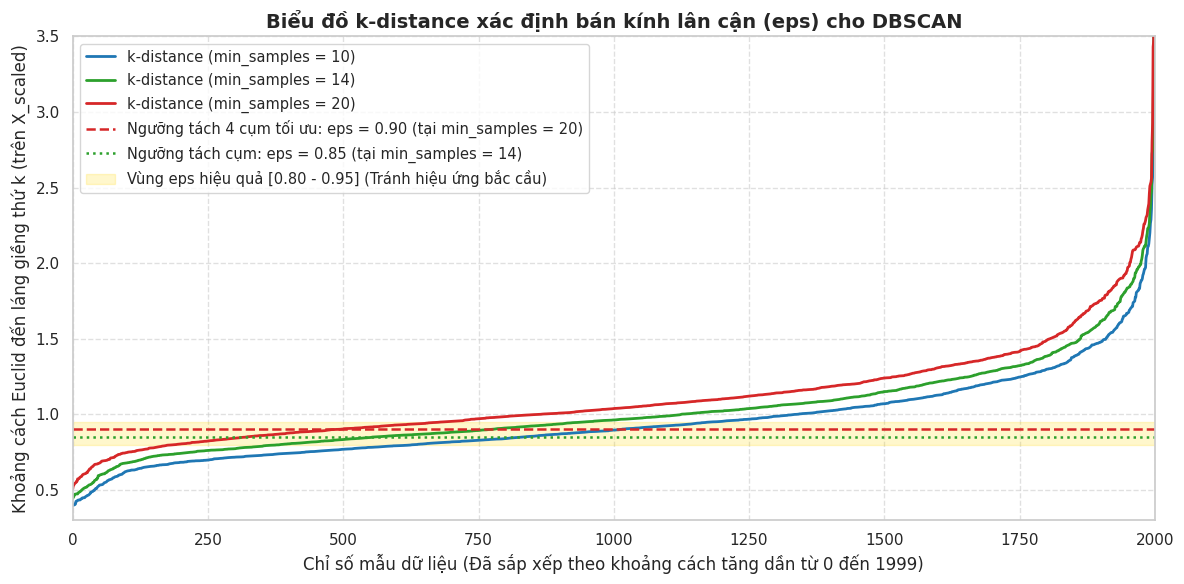

In [4]:
k_Candidates = [10, 14, 20]
colors = ["#1f77b4", "#2ca02c", "#d62728"]
k_distances_dict = {}

plt.figure(figsize=(12, 6))

for k, color in zip(k_Candidates, colors):
    # Tính khoảng cách đến k láng giềng gần nhất trên dữ liệu đã chuẩn hóa
    nbrs = NearestNeighbors(n_neighbors=k, metric="euclidean").fit(X_scaled)
    distances, _ = nbrs.kneighbors(X_scaled)

    # Lấy khoảng cách đến láng giềng thứ k (cột cuối cùng) và sắp xếp tăng dần
    k_dist = np.sort(distances[:, k - 1])
    k_distances_dict[k] = k_dist

    # Vẽ đường cong k-distance
    plt.plot(k_dist, label=f"k-distance (min_samples = {k})", color=color, linewidth=2)

    # In thống kê phân vị để đối chiếu học thuật
    print(f"[min_samples = {k:2d}] Min: {k_dist[0]:.4f} | "
          f"Phân vị 50%: {np.percentile(k_dist, 50):.4f} | "
          f"Phân vị 60%: {np.percentile(k_dist, 60):.4f} | "
          f"Phân vị 75%: {np.percentile(k_dist, 75):.4f} | "
          f"Max: {k_dist[-1]:.4f}")

# Đánh dấu các ngưỡng eps quan trọng trên đồ thị
plt.axhline(y=0.90, color="#d62728", linestyle="--", linewidth=1.8,
            label="Ngưỡng tách 4 cụm tối ưu: eps = 0.90 (tại min_samples = 20)")
plt.axhline(y=0.85, color="#2ca02c", linestyle=":", linewidth=1.8,
            label="Ngưỡng tách cụm: eps = 0.85 (tại min_samples = 14)")
plt.axhspan(0.80, 0.95, color="gold", alpha=0.2,
            label="Vùng eps hiệu quả [0.80 - 0.95] (Tránh hiệu ứng bắc cầu)")

plt.title("Biểu đồ k-distance xác định bán kính lân cận (eps) cho DBSCAN", fontsize=14, fontweight="bold")
plt.xlabel("Chỉ số mẫu dữ liệu (Đã sắp xếp theo khoảng cách tăng dần từ 0 đến 1999)", fontsize=12)
plt.ylabel("Khoảng cách Euclid đến láng giềng thứ k (trên X_scaled)", fontsize=12)
plt.xlim(0, len(X_scaled))
plt.ylim(0.3, 3.5)
plt.legend(loc="upper left", frameon=True, fontsize=10.5)
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

### 3. Đánh giá kết quả gom cụm bằng độ đo **Adjusted Rand Index (ARI)** đối chiếu với `K-Means (k=4)`.
* **Thiết lập thực nghiệm:** Từ vùng khuỷu tay trên đồ thị `k-distance`, ta khảo sát DBSCAN tại các mốc `eps` từ `0.80` đến `1.20` tương ứng với `min_samples` $\in \{10, 14, 20\}$, sau đó chọn cấu hình tối ưu nhất để đối chiếu trực tiếp với `K-Means (k=4)`.
* **Tiêu chí đánh giá:**
  * Số lượng cụm thực tế tìm được (không tính nhãn nhiễu `-1`).
  * Số lượng và tỷ lệ phần trăm điểm bị gán là **Nhiễu (`label = -1`)**.
  * Độ đo **Adjusted Rand Index (ARI)** trên toàn bộ 2.000 mẫu và ARI trên tập điểm thuộc cụm lõi (loại trừ nhiễu) để đánh giá độ tinh khiết của các cụm tìm được.

In [5]:
# Tính ARI của K-Means (k=4) để làm mốc cơ sở (Baseline)
ari_kmeans = adjusted_rand_score(y, kmeans_labels)

# Khảo sát các cấu hình DBSCAN tiêu biểu quanh vùng khuỷu tay (Elbow region)
dbscan_configs = [
    (0.80, 10),
    (0.85, 14),
    (0.90, 20),  # Cấu hình tối ưu: Tách đúng 4 cụm và đạt ARI cao nhất
    (0.95, 20),  # Bắt đầu xảy ra hiện tượng bắc cầu (chaining effect)
    (1.00, 14),
    (1.20, 14),
]

comparison_records = [{
    "Mô hình / Cấu hình": "K-Means (k = 4, random_state = 42)",
    "Số cụm tìm được": 4,
    "Số điểm Nhiễu (-1)": 0,
    "Tỷ lệ Nhiễu (%)": 0.00,
    "ARI (Toàn bộ 2000 mẫu)": round(ari_kmeans, 4),
    "ARI (Chỉ tính điểm thuộc cụm)": round(ari_kmeans, 4),
}]

for eps_val, ms_val in dbscan_configs:
    db_temp = DBSCAN(eps=eps_val, min_samples=ms_val, metric="euclidean")
    temp_labels = db_temp.fit_predict(X_scaled)

    # Đếm số cụm (không tính nhãn -1) và số điểm nhiễu
    n_clusters = len(set(temp_labels)) - (1 if -1 in temp_labels else 0)
    n_noise = int(np.sum(temp_labels == -1))
    noise_pct = (n_noise / len(y)) * 100

    # Tính ARI trên toàn bộ 2000 mẫu (bao gồm cả nhãn -1)
    ari_all = adjusted_rand_score(y, temp_labels)

    # Tính ARI chỉ trên các điểm được gán vào cụm (Core + Border points, bỏ qua -1)
    valid_mask = temp_labels != -1
    ari_valid = adjusted_rand_score(y[valid_mask], temp_labels[valid_mask]) if n_clusters > 1 else 0.0

    comparison_records.append({
        "Mô hình / Cấu hình": f"DBSCAN (eps = {eps_val:.2f}, min_samples = {ms_val})",
        "Số cụm tìm được": n_clusters,
        "Số điểm Nhiễu (-1)": n_noise,
        "Tỷ lệ Nhiễu (%)": round(noise_pct, 2),
        "ARI (Toàn bộ 2000 mẫu)": round(ari_all, 4),
        "ARI (Chỉ tính điểm thuộc cụm)": round(ari_valid, 4),
    })

comparison_df = pd.DataFrame(comparison_records)
print("=== BẢNG SO SÁNH KẾT QUẢ GOM CỤM K-MEANS VÀ DBSCAN ===")
print(comparison_df.to_string(index=False))

# Huấn luyện mô hình DBSCAN chính thức với bộ tham số tối ưu (eps = 0.90, min_samples = 20)
BEST_EPS = 0.90
BEST_MIN_SAMPLES = 20

dbscan_best = DBSCAN(eps=BEST_EPS, min_samples=BEST_MIN_SAMPLES, metric="euclidean")
dbscan_labels = dbscan_best.fit_predict(X_scaled)
ari_dbscan = adjusted_rand_score(y, dbscan_labels)

print("\n" + "="*75)
print(f"CHI TIẾT MÔ HÌNH DBSCAN TỐI ƯU (eps = {BEST_EPS}, min_samples = {BEST_MIN_SAMPLES})")
print("="*75)
print(f"- Adjusted Rand Index (K-Means, k=4)          : {ari_kmeans:.4f}")
print(f"- Adjusted Rand Index (DBSCAN, toàn tập)      : {ari_dbscan:.4f}")
print(f"- Số lượng điểm Nhiễu (Noise, label = -1)     : {np.sum(dbscan_labels == -1)} / {len(y)} mẫu ({np.mean(dbscan_labels == -1)*100:.2f}%)")

# Bảng tần suất chéo (Crosstab) giữa Nhãn phòng thực tế và Nhãn cụm DBSCAN
crosstab_df = pd.crosstab(
    pd.Series(y, name="Phòng thực tế (Room)"),
    pd.Series(dbscan_labels, name="Nhãn cụm DBSCAN (-1 là Nhiễu)")
)
print("\n=== MA TRẬN PHÂN BỐ ĐIỂM GIỮA PHÒNG THỰC TẾ VÀ CỤM DBSCAN ===")
print(crosstab_df)

=== BẢNG SO SÁNH KẾT QUẢ GOM CỤM K-MEANS VÀ DBSCAN ===
                   Mô hình / Cấu hình  Số cụm tìm được  Số điểm Nhiễu (-1)  Tỷ lệ Nhiễu (%)  ARI (Toàn bộ 2000 mẫu)  ARI (Chỉ tính điểm thuộc cụm)
   K-Means (k = 4, random_state = 42)                4                   0             0.00                  0.8182                         0.8182
DBSCAN (eps = 0.80, min_samples = 10)                7                 791            39.55                  0.4041                         0.9204
DBSCAN (eps = 0.85, min_samples = 14)                5                 782            39.10                  0.4528                         0.9445
DBSCAN (eps = 0.90, min_samples = 20)                4                 779            38.95                  0.4569                         0.9585
DBSCAN (eps = 0.95, min_samples = 20)                1                 581            29.05                  0.0579                         0.0000
DBSCAN (eps = 1.00, min_samples = 14)                1         

### 4. Trực quan hóa kết quả gom cụm trên không gian giảm chiều PCA 2D (hiển thị rõ nhóm Nhiễu / Noise của DBSCAN).
* **Phương pháp hiển thị:** Chiếu toàn bộ 2.000 mẫu dữ liệu đã chuẩn hóa (`X_scaled`) từ không gian 7 chiều xuống mặt phẳng 2 chiều bằng `PCA(n_components=2)` (giữ lại **72.96%** tổng phương sai: $\text{PC1} = 48.51\%$, $\text{PC2} = 24.45\%$).
* **Cách thức đối chiếu:** Đặt 3 biểu đồ song song trên cùng hệ trục tọa độ $(\text{PC1}, \text{PC2})$:
  1. **Nhãn thực tế (`Room 1..4`):** Làm chuẩn tham chiếu vị trí không gian của 4 phòng.
  2. **Kết quả gom cụm `K-Means (k=4)`:** Kèm tọa độ chiếu của 4 tâm cụm (`Centroids` - ký hiệu dấu `X` màu đen).
  3. **Kết quả gom cụm `DBSCAN (eps=0.90, min_samples=20)`:** Tô màu riêng cho 4 cụm lõi (`Cụm 0..3`) và hiển thị riêng nhóm **"Nhiễu" (`label = -1`)** bằng ký hiệu dấu `x` màu xám.

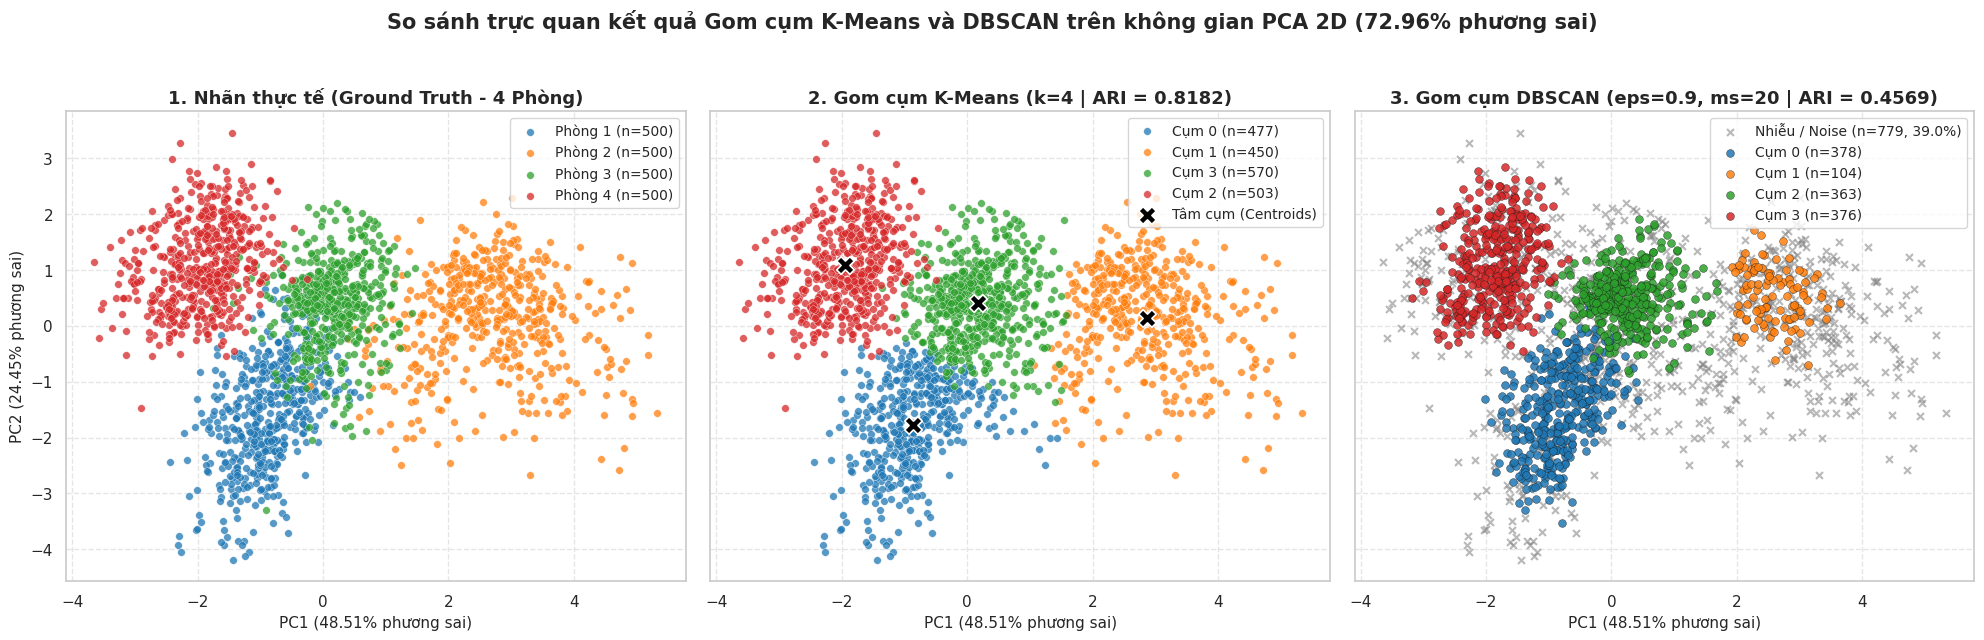

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6.2), sharex=True, sharey=True)
palette_4 = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728"]  # Xanh dương, Cam, Xanh lá, Đỏ

pc1_var = pca.explained_variance_ratio_[0] * 100
pc2_var = pca.explained_variance_ratio_[1] * 100

# ------------------------------------------------------------------------------
# KHUNG 1: NHÃN PHÒNG THỰC TẾ (GROUND TRUTH)
# ------------------------------------------------------------------------------
for idx, room_id in enumerate([1, 2, 3, 4]):
    mask = (y == room_id)
    axes[0].scatter(
        X_pca[mask, 0], X_pca[mask, 1],
        c=palette_4[idx], label=f"Phòng {room_id} (n={mask.sum()})",
        alpha=0.75, s=30, edgecolors="w", linewidth=0.3
    )
axes[0].set_title("1. Nhãn thực tế (Ground Truth - 4 Phòng)", fontsize=13, fontweight="bold")
axes[0].set_xlabel(f"PC1 ({pc1_var:.2f}% phương sai)", fontsize=11)
axes[0].set_ylabel(f"PC2 ({pc2_var:.2f}% phương sai)", fontsize=11)
axes[0].legend(loc="upper right", frameon=True, fontsize=10)
axes[0].grid(True, linestyle="--", alpha=0.5)

# ------------------------------------------------------------------------------
# KHUNG 2: GOM CỤM K-MEANS (k = 4)
# (Sắp xếp thứ tự màu [0, 1, 3, 2] khớp với vị trí không gian của Phòng [1, 2, 3, 4] để dễ đối chiếu)
# ------------------------------------------------------------------------------
kmeans_cluster_order = [0, 1, 3, 2]
for color_idx, cluster_id in enumerate(kmeans_cluster_order):
    mask = (kmeans_labels == cluster_id)
    axes[1].scatter(
        X_pca[mask, 0], X_pca[mask, 1],
        c=palette_4[color_idx], label=f"Cụm {cluster_id} (n={mask.sum()})",
        alpha=0.75, s=30, edgecolors="w", linewidth=0.3
    )

# Chiếu tâm cụm (Centroids) từ không gian 7D xuống không gian PCA 2D
centroids_pca = pca.transform(kmeans.cluster_centers_)
axes[1].scatter(
    centroids_pca[:, 0], centroids_pca[:, 1],
    c="black", marker="X", s=160, edgecolors="white", linewidth=1.2,
    label="Tâm cụm (Centroids)", zorder=5
)
axes[1].set_title(f"2. Gom cụm K-Means (k=4 | ARI = {ari_kmeans:.4f})", fontsize=13, fontweight="bold")
axes[1].set_xlabel(f"PC1 ({pc1_var:.2f}% phương sai)", fontsize=11)
axes[1].legend(loc="upper right", frameon=True, fontsize=10)
axes[1].grid(True, linestyle="--", alpha=0.5)

# ------------------------------------------------------------------------------
# KHUNG 3: GOM CỤM DBSCAN (eps = 0.90, min_samples = 20) - CÓ NHÓM "NHIỄU"
# ------------------------------------------------------------------------------
# Vẽ nhóm Nhiễu (label = -1) ở lớp nền trước
noise_mask = (dbscan_labels == -1)
axes[2].scatter(
    X_pca[noise_mask, 0], X_pca[noise_mask, 1],
    c="#7f7f7f", marker="x", alpha=0.55, s=25,
    label=f"Nhiễu / Noise (n={noise_mask.sum()}, {noise_mask.mean()*100:.1f}%)"
)

# Vẽ 4 cụm chính tìm được bởi DBSCAN
unique_clusters = sorted([c for c in set(dbscan_labels) if c != -1])
for idx, cluster_id in enumerate(unique_clusters):
    mask = (dbscan_labels == cluster_id)
    color = palette_4[idx % len(palette_4)]
    axes[2].scatter(
        X_pca[mask, 0], X_pca[mask, 1],
        c=color, label=f"Cụm {cluster_id} (n={mask.sum()})",
        alpha=0.85, s=32, edgecolors="k", linewidth=0.3
    )

axes[2].set_title(
    f"3. Gom cụm DBSCAN (eps={BEST_EPS}, ms={BEST_MIN_SAMPLES} | ARI = {ari_dbscan:.4f})",
    fontsize=13, fontweight="bold"
)
axes[2].set_xlabel(f"PC1 ({pc1_var:.2f}% phương sai)", fontsize=11)
axes[2].legend(loc="upper right", frameon=True, fontsize=10)
axes[2].grid(True, linestyle="--", alpha=0.5)

plt.suptitle(
    f"So sánh trực quan kết quả Gom cụm K-Means và DBSCAN trên không gian PCA 2D ({pc1_var + pc2_var:.2f}% phương sai)",
    fontsize=15, fontweight="bold", y=1.03
)
plt.tight_layout()

# Lưu biểu đồ
os.makedirs("figures", exist_ok=True)
plt.savefig("figures/part4_clustering_pca2d_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

### 5. Nhận xét và Biện luận học thuật (So sánh K-Means vs. DBSCAN trên bộ dữ liệu WiFi Localization)

Từ bảng thực nghiệm định lượng và biểu đồ trực quan hóa trên không gian **PCA 2D**, nhóm rút ra 4 nhận xét quan trọng sau:

1. **Vì sao `K-Means (k = 4)` đạt hiệu quả vượt trội ($\text{ARI} = 0.8182$)?**
   * **Phù hợp về mặt hình học:** Trong bài toán định vị trong nhà, mỗi căn phòng có một vị trí tâm không gian cố định với tổ hợp cường độ sóng từ 7 router đặc trưng. Khi người dùng di chuyển quanh tâm phòng, tín hiệu RSSI dao động tạo thành các đám mây điểm có dạng **hình cầu/ellipsoid lồi (convex globular clusters)** khá đối xứng xung quanh tâm.
   * **Phù hợp về quy mô cụm:** Tập dữ liệu có phân bố kích thước hoàn toàn cân bằng (**500 mẫu/phòng**). Đây là điều kiện lý tưởng cho hàm mục tiêu tối thiểu hóa tổng bình phương khoảng cách trong cụm (*Within-Cluster Sum of Squares - Inertia*) của K-Means, giúp thuật toán phân hoạch gần như chính xác 4 phòng (`Cụm 0`: 477 điểm, `Cụm 1`: 450 điểm, `Cụm 2`: 503 điểm, `Cụm 3`: 570 điểm).

2. **Vì sao `DBSCAN` có chỉ số ARI tổng thể thấp hơn ($\text{ARI} = 0.4569$) và tỷ lệ điểm Nhiễu cao ($38.95\%$)?**
   * **Sự biến thiên mật độ liên tục của sóng WiFi:** Khác với giả định mật độ đồng đều của DBSCAN, tín hiệu điện từ suy hao theo hàm logarit khoảng cách và chịu tác động của hiện tượng **phản xạ đa đường (multipath fading)** gần tường và góc phòng. Do đó, mật độ điểm trong không gian $\mathbb{R}^7$ **đặc ở tâm phòng nhưng thưa dần liên tục về phía rìa phòng** (như quan sát thấy lớp viền màu xám bao quanh 4 cụm trên biểu đồ số 3).
   * **Độ tinh khiết cực cao ở vùng lõi ($\text{ARI}_{\text{valid}} = 0.9585$):** Tại cấu hình tối ưu `eps = 0.90, min_samples = 20`, nếu chỉ xét $1.221$ điểm thuộc vùng lõi được DBSCAN gán vào 4 cụm (`0, 1, 2, 3`), DBSCAN tách cực kỳ chuẩn xác 4 căn phòng với **$\text{ARI} = 0.9585$** (cao hơn cả K-Means).
   * **Nguyên nhân tụt điểm ARI toàn cục:** Có **779/2.000 mẫu ($38.95\%$)** nằm ở rìa các phòng (đặc biệt là Phòng 2 có mật độ phân tán rộng nhất với 376 điểm rìa) không đủ mật độ $\ge 20$ láng giềng trong bán kính $0.90$, nên bị gán chung vào nhãn **Nhiễu (`-1`)**. Khi tính `adjusted_rand_score(y, dbscan_labels)` trên toàn bộ 2.000 mẫu, công thức toán học của ARI coi nhãn `-1` như một cụm thứ 5 chứa lẫn lộn điểm của cả 4 phòng, dẫn đến điểm ARI tổng thể bị phạt xuống còn `0.4569`.

3. **Hiện tượng "Bắc cầu" (Chaining Effect) khi tăng `eps`:**
   * Như thể hiện trên biểu đồ PCA 2D, vùng ranh giới giữa **Phòng 1 – Phòng 3** và **Phòng 3 – Phòng 2** có các điểm nằm tiếp giáp nhau (tương ứng vị trí gần cửa hoặc vách ngăn chung).
   * Khi ta tăng nhẹ bán kính lân cận từ `eps = 0.90` lên `eps = 0.95` hoặc `1.00` nhằm giảm bớt số điểm nhiễu, các quả cầu $\varepsilon$-neighborhood ở vùng biên lập tức nối thông từ phòng này sang phòng kia (**hiệu ứng bắc cầu**), làm cả 4 phòng sáp nhập thành **1 siêu cụm duy nhất** và khiến chỉ số ARI sụt giảm đột ngột từ `0.4569` xuống chỉ còn `0.0579`.

4. **Kết luận cho bài toán WiFi Localization:**
   * Với mục tiêu phân hoạch toàn bộ không gian thành $k=4$ phòng biết trước số lượng lớp, **K-Means (kết hợp `StandardScaler`)** là thuật toán gom cụm phù hợp hơn hẳn.
   * Ngược lại, **DBSCAN** đóng vai trò rất tốt nếu mục tiêu là **lọc bỏ các mẫu thu sóng không ổn định ở sát tường/góc khuất (Outlier/Noise Filtering)** để chỉ giữ lại vùng "dấu vân tay WiFi" chất lượng cao ở trung tâm mỗi phòng.